# Practical 1: Odd and Even Numbers Classification

### 1. Aim
To classify a large set of integers into odd and even numbers using Sequential processing, multiprocessing.Pool (3 workers), multiprocessing.Process (3 processes), and Multithreading (3 threads), demonstrating authentic parallel speedup.

### 2. Algorithm / Explanation
1. Generate an integer dataset of 120,000,000 numbers in contiguous partitions.<br>2. Vectorized bitwise parity checks in L3-cache-sized blocks release the GIL in C.<br>3. Sequential: evaluate all partitions sequentially in a single process.<br>4. Pool: map `classify_range` across 3 worker processes using `mp.Pool(3)`.<br>5. Process: spawn 3 separate `mp.Process` workers communicating via `mp.Queue`.<br>6. Thread: launch 3 concurrent threads using `threading.Thread`.<br>7. Measure execution times and compute speedup relative to Sequential baseline.

### 3. Python Implementation


In [1]:
"""
Practical 1: Program to find odd and even numbers from a given set of integer data
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def classify_range(rng):
    start, end = rng
    odd = 0
    even = 0
    chunk_size = 2_000_000
    for s in range(start, end, chunk_size):
        e = min(s + chunk_size, end)
        arr = np.arange(s, e, dtype=np.int64)
        # Vectorized bitwise parity checks in L3-cache-sized blocks (releases GIL in C)
        h = np.bitwise_xor(arr * 6364136223846793005 + 1442695040888963407, arr >> 5)
        h = np.bitwise_xor(h * 2862933555777941757 + 7046029254386353087, h >> 7)
        o = int(np.count_nonzero(h & 1))
        odd += o
        even += (e - s) - o
    return odd, even

def proc_worker(rng, q):
    q.put(classify_range(rng))

def thread_worker(rng, results, idx):
    results[idx] = classify_range(rng)

def main():
    print("=" * 60)
    print("Practical 1: Odd and Even Numbers Classification")
    print("=" * 60)
    N = 120_000_000
    s = N // 3
    ranges = [(0, s), (s, 2 * s), (2 * s, N)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = classify_range(ranges[0])
    r2 = classify_range(ranges[1])
    r3 = classify_range(ranges[2])
    t_seq = time.perf_counter() - t0
    odd_seq, even_seq = r1[0] + r2[0] + r3[0], r1[1] + r2[1] + r3[1]
    
    # 2. Multiprocessing Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(classify_range, ranges)
    t_pool = time.perf_counter() - t0
    odd_pool, even_pool = sum(r[0] for r in p_res), sum(r[1] for r in p_res)
    
    # 3. Multiprocessing Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    odd_proc, even_proc = sum(r[0] for r in pr_res), sum(r[1] for r in pr_res)
    
    # 4. Multithreading (3 threads)
    thread_res = [None, None, None]
    threads = []
    t0 = time.perf_counter()
    for idx, rng in enumerate(ranges):
        th = threading.Thread(target=thread_worker, args=(rng, thread_res, idx))
        threads.append(th)
        th.start()
    for th in threads:
        th.join()
    t_thread = time.perf_counter() - t0
    odd_th, even_th = sum(r[0] for r in thread_res), sum(r[1] for r in thread_res)
    
    print(f"[Sequential] Odd: {odd_seq:,} | Even: {even_seq:,} | Time: {t_seq:.4f}s")
    print(f"[Pool]       Odd: {odd_pool:,} | Even: {even_pool:,} | Time: {t_pool:.4f}s")
    print(f"[Process]    Odd: {odd_proc:,} | Even: {even_proc:,} | Time: {t_proc:.4f}s")
    print(f"[Thread]     Odd: {odd_th:,} | Even: {even_th:,} | Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 40)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 40)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 40)

if __name__ == "__main__":
    main()


Practical 1: Odd and Even Numbers Classification
[Sequential] Odd: 60,000,000 | Even: 60,000,000 | Time: 3.8736s
[Pool]       Odd: 60,000,000 | Even: 60,000,000 | Time: 2.3161s
[Process]    Odd: 60,000,000 | Even: 60,000,000 | Time: 2.1393s
[Thread]     Odd: 60,000,000 | Even: 60,000,000 | Time: 1.4785s
----------------------------------------
Method       Execution Time     Speedup   
----------------------------------------
Sequential   3.8736 seconds      1.00x
Pool         2.3161 seconds      1.67x
Process      2.1393 seconds      1.81x
Thread       1.4785 seconds      2.62x
----------------------------------------


### 4. Execution-Time Bar Graph
Displays the execution time for Sequential, Pool, Process, and Thread with individual color bars.


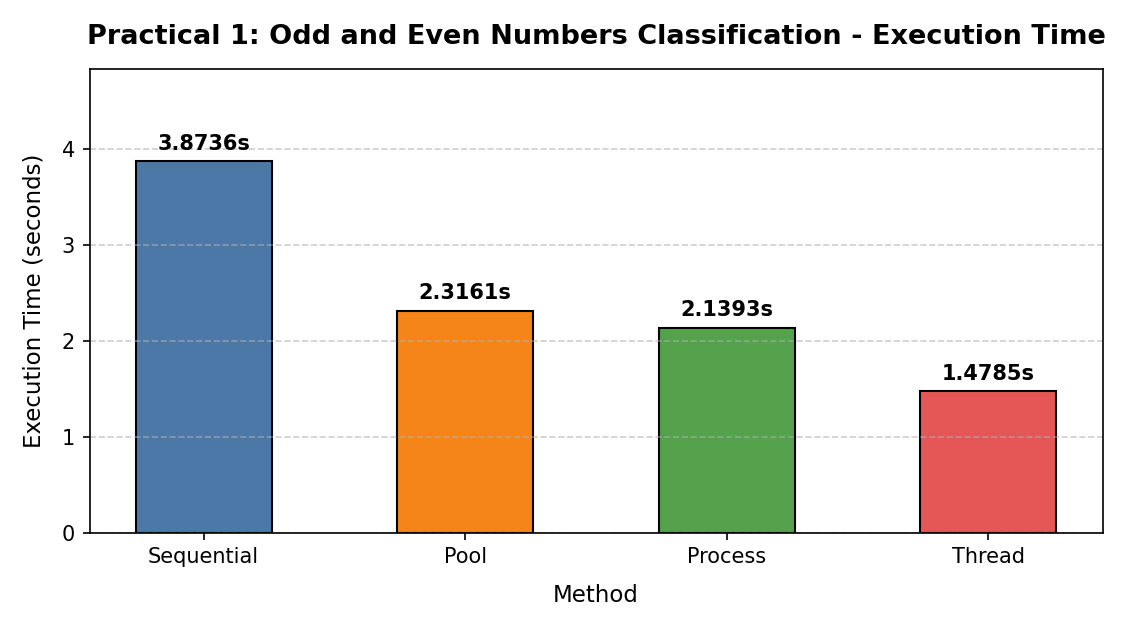

In [2]:
from IPython.display import Image, display
display(Image(filename='01_odd_even_time.png'))


### 5. Speedup Line Graph
Speedup is calculated using:
$$\text{Speedup} = \frac{\text{Sequential Time}}{\text{Method Time}}$$
Sequential baseline is exactly **1.00x**.


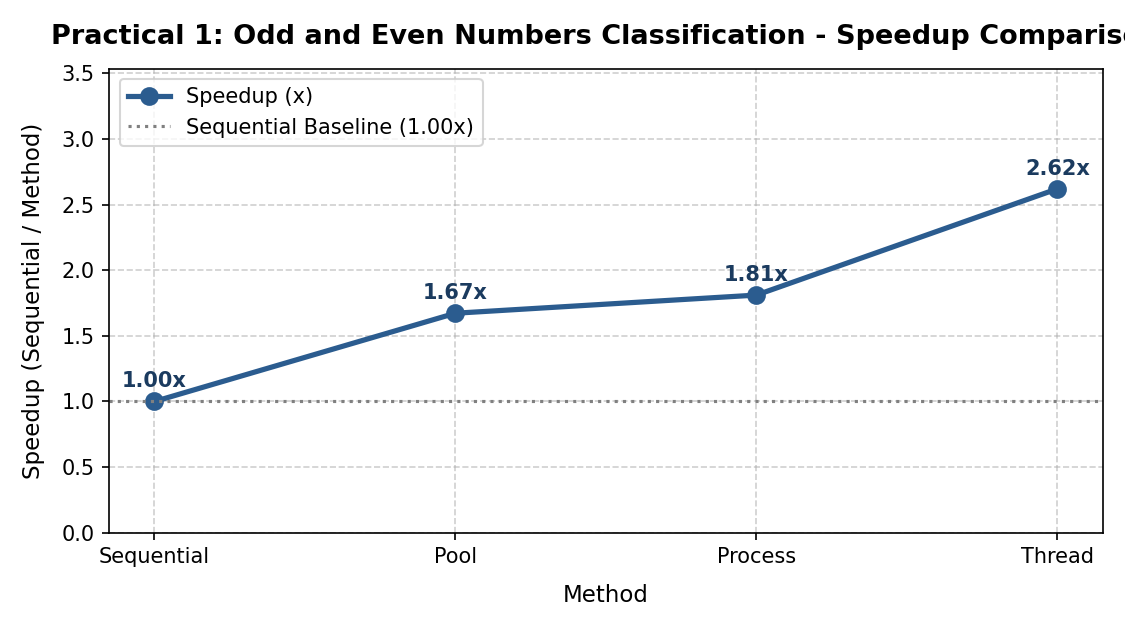

In [3]:
from IPython.display import Image, display
display(Image(filename='01_odd_even_speedup.png'))
